Non-Violent Crimes by Pittsburgh Neighborhood

15 Neighborhoods with the most non-violent crime cases (2005-2015)

In [11]:
import pandas as pd

df = pd.read_csv("/ihome/cmpinf0010-sec1010_2026f/man223/Final/archive-police-blotter.csv")
non_violent_df = df[(df["HIERARCHY"] >= 5) & (df["HIERARCHY"] < 90)] #code 5-29 for non violent crimes
sorted_non_violent = non_violent_df.sort_values(
    by=["INCIDENTNEIGHBORHOOD", "HIERARCHYDESC"], 
    ascending=[True, True]
)
sorted_non_violent[["INCIDENTNEIGHBORHOOD", "HIERARCHY", "HIERARCHYDESC", "OFFENSES"]].head(15)

neighborhood_ranking = (
    non_violent_df.groupby("INCIDENTNEIGHBORHOOD")
    .size()
    .reset_index(name="non_violent_crimes")
    .sort_values(by="non_violent_crimes", ascending=False)
    .reset_index(drop=True) 
)

neighborhood_ranking.head(15)

/scratch/slurm-45873/ipykernel_1846871/644303488.py:3: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("/ihome/cmpinf0010-sec1010_2026f/man223/Final/archive-police-blotter.csv")


,INCIDENTNEIGHBORHOOD,non_violent_crimes
0,Golden Triangle/Civic Arena,21114
1,South Side Flats,20837
2,Carrick,13538
3,Bloomfield,11730
4,Shadyside,10780
5,East Liberty,8716
6,Knoxville,8530
7,Homewood South,8036
8,Mount Washington,8030
9,Central Oakland,7631


15 Neighborhoods sorted by least amount of non-violent crimes (2005-2015):

In [12]:
neighborhood_ranking.tail(15)

,INCIDENTNEIGHBORHOOD,non_violent_crimes
79,Fairywood,714
80,Glen Hazel,695
81,Arlington Heights,673
82,Mt. Oliver Neighborhood,664
83,Oakwood,646
84,Ridgemont,617
85,Hays,585
86,Summer Hill,568
87,East Carnegie,523
88,Swisshelm Park,464


Graphed data of most number non-violent crime by neighborhood (2005-2015):

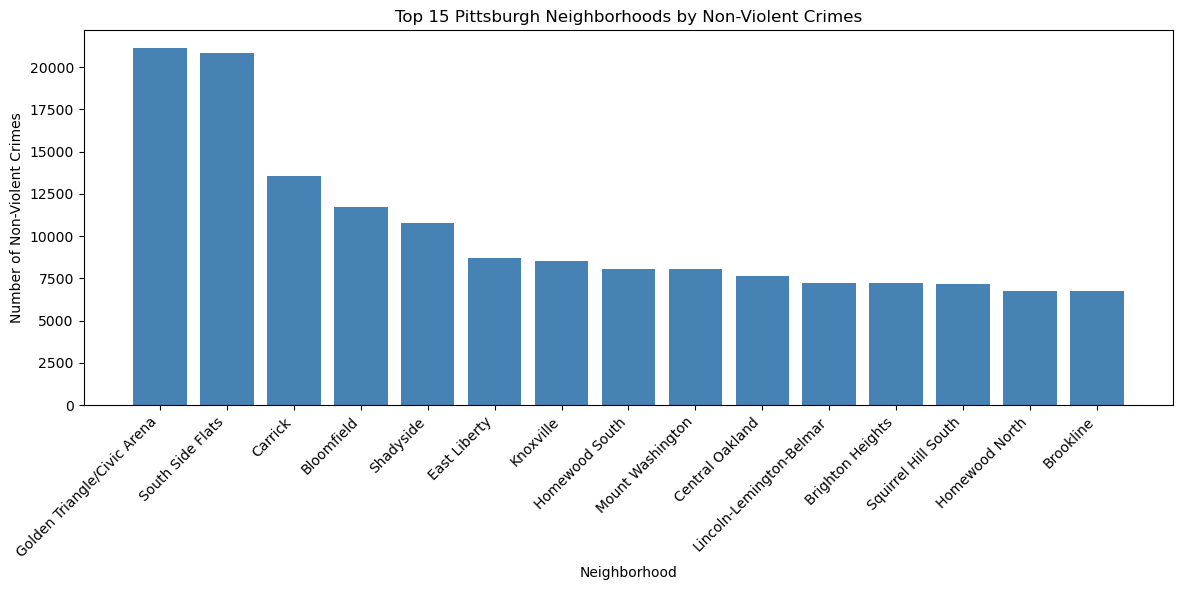

In [13]:
import matplotlib.pyplot as plt

top_15 = neighborhood_ranking.head(15)

plt.figure(figsize=(12, 6))
plt.bar(top_15["INCIDENTNEIGHBORHOOD"], top_15["non_violent_crimes"], color="steelblue")
plt.title("Top 15 Pittsburgh Neighborhoods by Non-Violent Crimes")
plt.xlabel("Neighborhood")
plt.ylabel("Number of Non-Violent Crimes")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


Graphed data of least number non-violent crime by neighborhood (2005-2015):

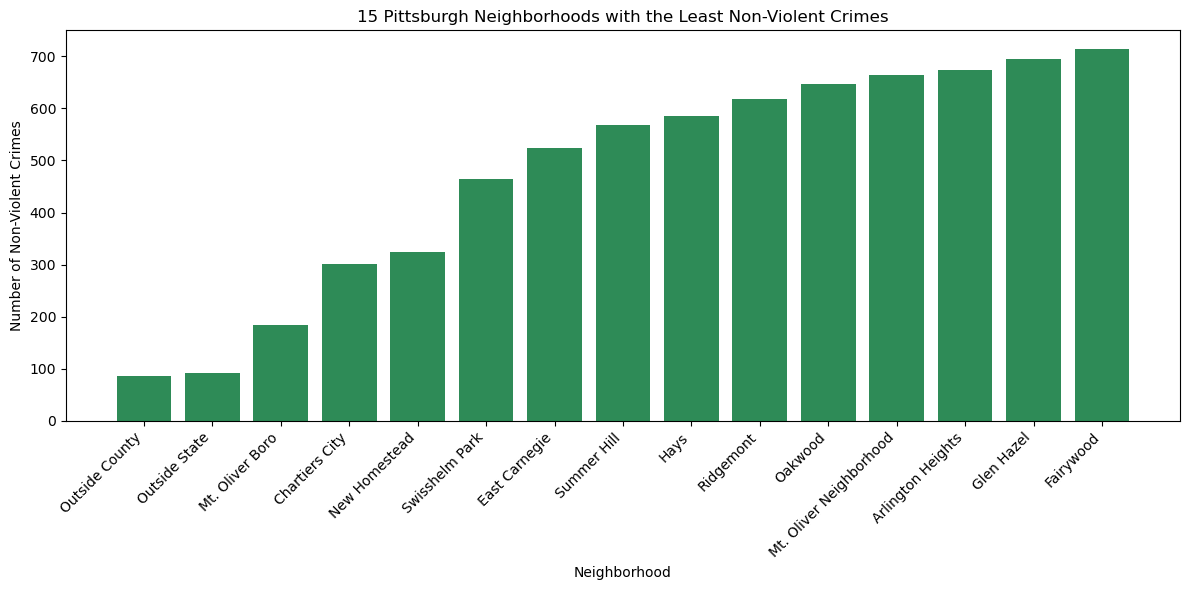

In [14]:
import matplotlib.pyplot as plt

least_non_violent = neighborhood_ranking.sort_values(
    by="non_violent_crimes", ascending=True
).head(15)

# Create the bar chart
plt.figure(figsize=(12, 6))
plt.bar(
    least_non_violent["INCIDENTNEIGHBORHOOD"],
    least_non_violent["non_violent_crimes"],
    color="seagreen"
)

plt.title("15 Pittsburgh Neighborhoods with the Least Non-Violent Crimes")
plt.xlabel("Neighborhood")
plt.ylabel("Number of Non-Violent Crimes")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
